# Task 3 Handling missing data

## Imports

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import SimpleImputer, KNNImputer, IterativeImputer
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.model_selection import cross_val_predict
from xgboost import XGBRegressor
from catboost import CatBoostRegressor, Pool

## Auxiliary functions

In [4]:
def cMSE(y, y_hat, c):
    err = y-y_hat
    err = (1-c)*err**2 + c*np.maximum(0,err)**2
    return np.sum(err)/err.shape[0]
    
def plot_y_yhat(y_test, y_pred, plot_title="plot"):
    label = 'SurvivalTime'
    MAX = 500

    if len(y_test) > MAX:
        idx = np.random.choice(len(y_test), MAX, replace=False)
    else:
        idx = np.arange(len(y_test))

    plt.figure(figsize=(6, 6))
    x0 = np.min(y_test[idx])
    x1 = np.max(y_test[idx])
    plt.scatter(y_test[idx], y_pred[idx], alpha=0.7)
    plt.xlabel(f'True {label}')
    plt.ylabel(f'Predicted {label}')
    plt.plot([x0, x1], [x0, x1], color='red')
    plt.title(f'True vs Predicted {label}')
    plt.axis('square')
    plt.savefig(plot_title + '.pdf')
    plt.show()
    
def save_predictions(predictions, path):
    df = pd.DataFrame({
        'id': range(len(predictions)),
        '0': predictions
    })
    
    df.to_csv(path, index=False)
    
def model_metrics(y_true, y_pred):
    error = y_true - y_pred
    metrics = {
        'Max Error': np.max(np.abs(error)),
        'Min Error': np.min(np.abs(error)),
        'Mean Error': np.mean(np.abs(error)),
        'Standard Deviation': np.std(error)
    }
    return metrics
    
def evaluate_model(X, y, c, model, show_cmse=True, show_plot=False):
    X_train, X_test, y_train, y_test, c_train, c_test = train_test_split(X, y, c, test_size=0.2, random_state=30)
    
    y_pred_cv = cross_val_predict(model, X_train, y_train, cv=10)
    cMSE_cv = cMSE(y_train, y_pred_cv, c_train)
    
    model.fit(X_train, y_train)
    
    y_pred = model.predict(X_test)
    cMSE_test = cMSE(y_test, y_pred, c_test)
    
    if show_cmse:
        print(f"CV cMSE: {cMSE_cv}")
        print(f"Test cMSE: {cMSE_test}")
    
    if show_plot:
        plot_y_yhat(y_test, y_pred, plot_title="y_yhat_plot")
    
    return model, cMSE_cv, cMSE_test, model_metrics(y_test, y_pred)

## Data preprocessing

In [5]:
df = pd.read_csv('./mlNOVA/train_data.csv')
df.drop(columns=['id'], inplace=True)
df = df[df['SurvivalTime'].notna()]

In [6]:
X = df.drop(columns=['SurvivalTime', 'Censored'])
y = df['SurvivalTime']
c = df['Censored']

print(f"X shape: {X.shape}")
print(f"y shape: {y.shape}")
print(f"c shape: {c.shape}")

X = np.array(X)
y = np.array(y)
c = np.array(c)

X shape: (240, 7)
y shape: (240,)
c shape: (240,)


## Task 3.1 Missing data imputation

### Completing missing data

### Evaluating imputation on the baseline

Pipeline for Linear Regression with Standard Scaler

In [30]:
linear_reg = make_pipeline(StandardScaler(), LinearRegression())

#### Simple imputer

##### Mean

CV cMSE: 2.6095256381326184
Test cMSE: 2.421082353209675


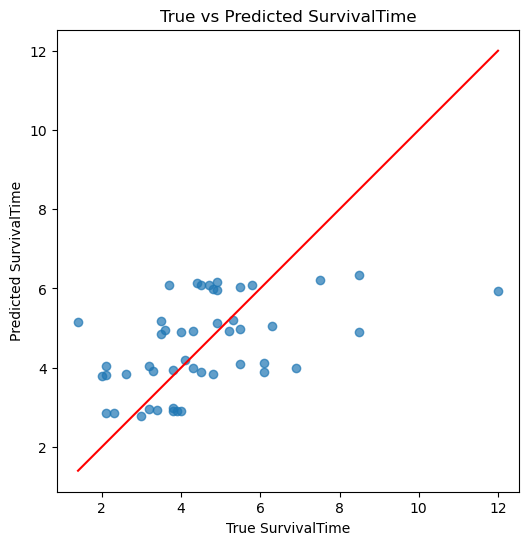

In [10]:
X_imp_simple_mean = SimpleImputer(strategy='mean').fit_transform(X)
_, _, _, sm_imp_metrics = evaluate_model(X_imp_simple_mean, y, c, linear_reg, show_plot=True)

##### Median

In [11]:
X_imp_simple_median = SimpleImputer(strategy = 'median').fit_transform(X)
_, _, _, _ = evaluate_model(X_imp_simple_median, y, c, linear_reg)

CV cMSE: 2.6621454948600958
Test cMSE: 2.4227557451652557


##### Most frequent

In [12]:
X_imp_simple_most_freq = SimpleImputer(strategy = 'most_frequent').fit_transform(X)
_, _, _, _ = evaluate_model(X_imp_simple_most_freq, y, c, linear_reg)

CV cMSE: 2.6621454948600958
Test cMSE: 2.4227557451652557


##### Mean strategy on best model from task 2 (KNN with k=11)

K = 11

In [32]:
X_imp_sm = SimpleImputer(strategy='mean').fit_transform(X)
knn_reg = make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=11))
_, _, _, sm_metrics = evaluate_model(X_imp_sm, y, c, model=knn_reg)

CV cMSE: 2.560508350550964
Test cMSE: 2.9572469008264464


#### KNN imputer

##### Find best K for KNN imputer with cross validation

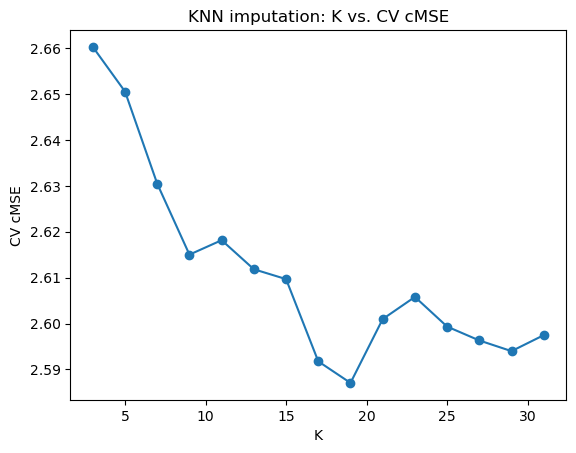

In [14]:
k_values = [3, 5, 7, 9, 11, 13, 15, 17, 19, 21, 23, 25, 27, 29, 31]
knn_scores = []

for k in k_values:
    imputer_knn = KNNImputer(n_neighbors=k)
    X_imp_knn = imputer_knn.fit_transform(X)
    _, score, _, _ = evaluate_model(X_imp_knn, y, c, model=linear_reg, show_cmse=False)
    knn_scores.append(score)

plt.plot(k_values, knn_scores, marker='o')
plt.xlabel("K")
plt.ylabel("CV cMSE")
plt.title("KNN imputation: K vs. CV cMSE")
plt.show()

Best K for KNN imputer is 19

CV cMSE: 2.587060500732423
Test cMSE: 2.4391886465016195


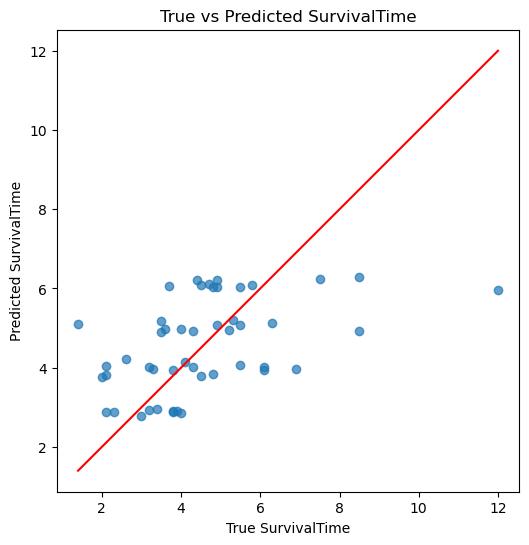

In [15]:
X_imp_knn = KNNImputer(n_neighbors=19).fit_transform(X)
_, _, _, knn_imp_metrics = evaluate_model(X_imp_knn, y, c, model=linear_reg, show_plot=True)

##### KNN imputation with k=19 on best model from task 2 (KNN with k=11)

K = 11

In [33]:
X_imp_knn = KNNImputer(n_neighbors=19).fit_transform(X)
knn_reg = make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=11))
_, _, _, knn_metrics = evaluate_model(X_imp_knn, y, c, model=knn_reg)

CV cMSE: 2.4695781680440767
Test cMSE: 2.9259108126721762


#### Iterative imputer

##### Evaluation

CV cMSE: 2.614387285895696
Test cMSE: 2.4214396677414647


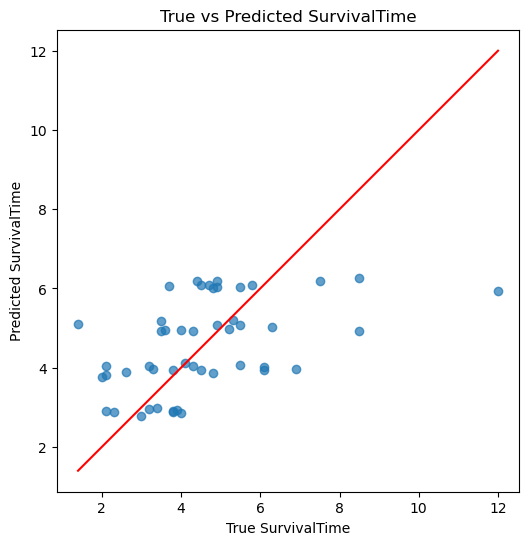

In [17]:
X_imp_iter = IterativeImputer().fit_transform(X)
_, _, _, iter_imp_metrics = evaluate_model(X_imp_iter, y, c, model=linear_reg, show_plot=True)

##### Iterative imputation on best model from task 2 (KNN with k = 11)

K = 11

In [34]:
X_imp_iter = IterativeImputer().fit_transform(X)
knn_reg = make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=11))
_, _, _, iter_metrics = evaluate_model(X_imp_iter, y, c, model=knn_reg)

CV cMSE: 2.551123450413223
Test cMSE: 2.858013085399449


### Compare metrics with task 1.2

Display table with metrics

#### Linear regression

In [20]:
table = pd.DataFrame({
    'Simple Mean imputation': sm_imp_metrics,
    'KNN with K=19 imputation': knn_imp_metrics,
    'Iterative imputation': iter_imp_metrics
})

table.T.head()

,Max Error,Min Error,Mean Error,Standard Deviation
Simple Mean imputation,6.075789,0.084432,1.280692,1.682250
KNN with K=19 imputation,6.050910,0.035233,1.296114,1.693560
Iterative imputation,6.075599,0.030936,1.283452,1.686608


## Task 3.2 Train models that do not require imputation

### Data preprocessing, no imputation

In [8]:
df = pd.read_csv('./mlNOVA/train_data.csv')
df.drop(columns=['id'], inplace=True)
df = df[df['SurvivalTime'].notna()]

In [9]:
X = df.drop(columns=['SurvivalTime', 'Censored'])
y = df['SurvivalTime']
c = df['Censored']

print(f"X shape: {X.shape}")
print(f"y shape: {y.shape}")
print(f"c shape: {c.shape}")

X = np.array(X)
y = np.array(y)
c = np.array(c)

# Split the data into train and test sets (with missing values)
X_train, X_test, y_train, y_test, c_train, c_test = train_test_split(X, y, c, test_size=0.2, random_state=30)

X shape: (240, 7)
y shape: (240,)
c shape: (240,)


### Tree based methods

#### Function for training tree-based model

In [10]:
def train_tree_based_model(X, y, c, show_cmse=True, show_plot=False, type=None, **kwargs):
    if type == 'decision_tree':
        model = DecisionTreeRegressor(random_state=30, **kwargs)
    elif type == 'random_forest':
        model = RandomForestRegressor(random_state=30, **kwargs)
    elif type == 'xgboost':
        model = XGBRegressor(random_state=30, **kwargs)
    elif type == 'catboost':
        model = CatBoostRegressor(random_state=30, **kwargs)
    elif type == 'hist_gradient_boost':
        model = HistGradientBoostingRegressor(random_state=30, **kwargs)
    else:
        raise ValueError(f"Unsupported model type: {type}")
    
    return evaluate_model(X, y, c, model, show_cmse=show_cmse, show_plot=show_plot)

#### Select best number of features for random forest

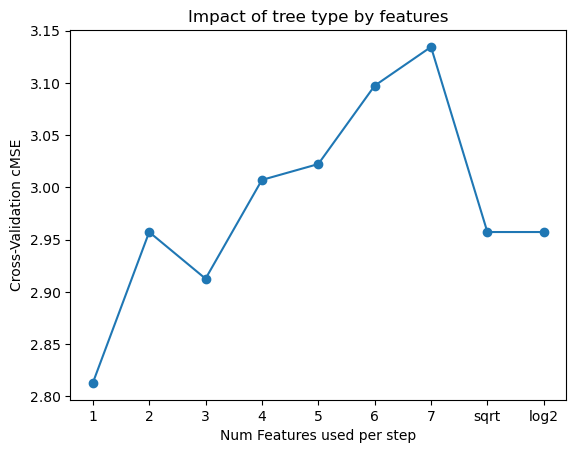

In [44]:
features = [1, 2, 3, 4, 5, 6, 7, 'sqrt', 'log2']
random_forest_cMSEs = []

for n_features in features:
    _, rf_cMSE, _, _ = train_tree_based_model(
        X, y, c, show_cmse=False, type='random_forest', max_features=n_features)
    random_forest_cMSEs.append(rf_cMSE)
    
plt.plot(features, random_forest_cMSEs, label="Random Forest", marker='o')
plt.xlabel("Num Features used per step")
plt.ylabel("Cross-Validation cMSE")
plt.title("Impact of tree type by features")
plt.show()

#### Try out all tree-based models

In [46]:
depths = range(1, 11)
dt_scores = []
rf_scores = []
xgb_scores = []
cat_scores = []
hgb_scores = []

for d in depths:
    _, dt_score, _, _ = train_tree_based_model(
        X, y, c, show_cmse=False, type='decision_tree', max_depth=d)
    dt_scores.append(dt_score)

    _, rf_score, _, _ = train_tree_based_model(
        X, y, c, show_cmse=False, type='random_forest', max_depth=d, max_features='sqrt')
    rf_scores.append(rf_score)

    _, xgb_score, _, _ = train_tree_based_model(
        X, y, c, show_cmse=False, type='xgboost', max_depth=d, learning_rate=0.05)
    xgb_scores.append(xgb_score)

    _, cat_score, _, _ = train_tree_based_model(
        X, y, c, show_cmse=False, type='catboost', max_depth=d, learning_rate=0.01, silent=True)
    cat_scores.append(cat_score)

    _, hgb_score, _, _ = train_tree_based_model(
        X, y, c, show_cmse=False, type='hist_gradient_boost', max_depth=d)
    hgb_scores.append(hgb_score)

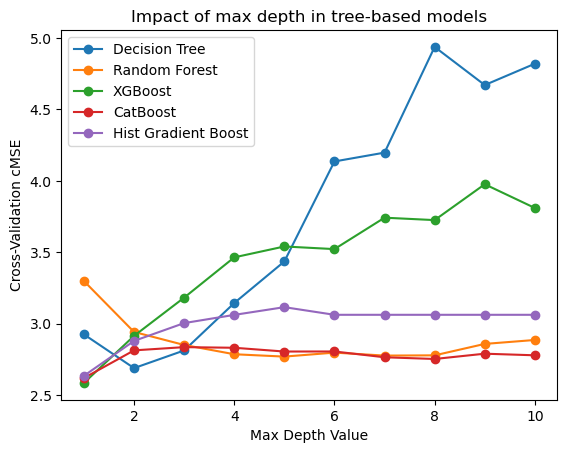

In [47]:
plt.plot(depths, dt_scores, label="Decision Tree", marker='o')
plt.plot(depths, rf_scores, label="Random Forest", marker='o')
plt.plot(depths, xgb_scores, label="XGBoost", marker='o')
plt.plot(depths, cat_scores, label="CatBoost", marker='o')
plt.plot(depths, hgb_scores, label="Hist Gradient Boost", marker='o')
plt.xlabel("Max Depth Value")
plt.ylabel("Cross-Validation cMSE")
plt.title("Impact of max depth in tree-based models")
plt.legend()
plt.show()

#### Run the best models

In [11]:
print("Decision Tree")
dt_model, dt_cMSE, _, dt_metrics = train_tree_based_model(
    X_train, y_train, c_train, type='decision_tree', max_depth=2)

print("Random Forest")
rf_model, rf_cMSE, _, rf_metrics = train_tree_based_model(
    X_train, y_train, c_train, type='random_forest', max_depth=5, max_features='sqrt')

print("XGBoost")
xgb_model, xgb_cMSE, _, xgb_metrics = train_tree_based_model(
    X_train, y_train, c_train, type='xgboost', max_depth=1, learning_rate=0.05)

print("CatBoost")
cat_model, cat_cMSE, _, cat_metrics = train_tree_based_model(
    X_train, y_train, c_train, type='catboost', max_depth=1, learning_rate=0.01, silent=True)

print("Histogram Gradient Boosting")
hgb_model, hgb_cMSE, _, hgb_metrics = train_tree_based_model(
    X_train, y_train, c_train, type='hist_gradient_boost', max_depth=1)

Decision Tree
CV cMSE: 2.6563479084261195
Test cMSE: 2.9890687244692256
Random Forest
CV cMSE: 2.871713041831807
Test cMSE: 2.950743689819371
XGBoost
CV cMSE: 2.6385957818916106
Test cMSE: 2.6005472025314704
CatBoost
CV cMSE: 2.6729463228338024
Test cMSE: 2.859406558540088
Histogram Gradient Boosting
CV cMSE: 2.691191661229865
Test cMSE: 2.7995394757854544


#### Compare CMSE across models

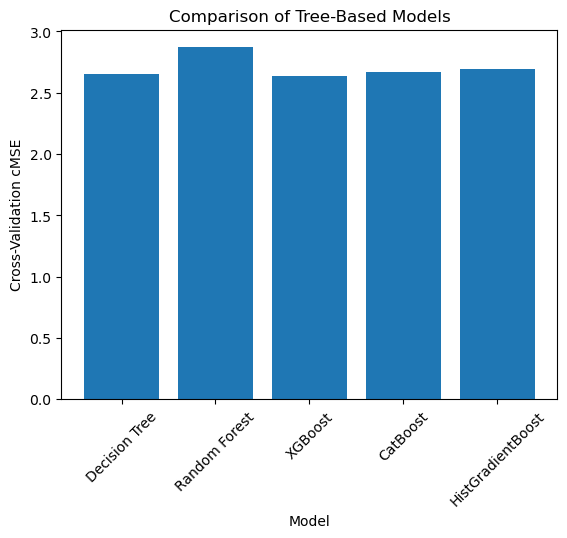

In [46]:
models = ['Decision Tree', 'Random Forest', 'XGBoost', 'CatBoost', 'HistGradientBoost']
cMSE_values = [dt_cMSE, rf_cMSE, xgb_cMSE, cat_cMSE, hgb_cMSE]

plt.bar(models, cMSE_values)
plt.xlabel("Model")
plt.ylabel("Cross-Validation cMSE")
plt.title("Comparison of Tree-Based Models")
plt.xticks(rotation=45)
plt.show()

Metrics

In [47]:
table = pd.DataFrame({
    'Decision Tree': dt_metrics,
    'Random Forest': rf_metrics,
    'XGBoost': xgb_metrics,
    'CatBoost': cat_metrics,
    'Histogram GB': hgb_metrics
})

table.T.head()

,Max Error,Min Error,Mean Error,Standard Deviation
Decision Tree,5.632353,0.086364,1.284895,1.752263
Random Forest,5.407375,0.014066,1.325817,1.756655
XGBoost,5.293990,0.060381,1.249277,1.650778
CatBoost,5.418007,0.055955,1.273691,1.727053
Histogram GB,5.461786,0.001279,1.281798,1.712220


### CatBoost: Accelerated Failure Time (AFT) CatBoost applied to the assignment data.

Followed the following tutorial: https://github.com/catboost/tutorials/blob/master/regression/survival.ipynb

#### Pre-processing

In [51]:
df = pd.read_csv('./mlNOVA/train_data.csv')
df.drop(columns=['id'], inplace=True)
df = df[df['SurvivalTime'].notna()]

In [52]:
X = df.drop(columns=['SurvivalTime', 'Censored'])
y = df['SurvivalTime']
c = df['Censored']

print(f"X shape: {X.shape}")
print(f"y shape: {y.shape}")
print(f"c shape: {c.shape}")

X = np.array(X)
y = np.array(y)
c = np.array(c)

X_train, X_test, y_train, y_test, c_train, c_test = train_test_split(X, y, c, test_size=0.2, random_state=42)

df['y_lower'] = df['SurvivalTime']
df['y_upper'] = np.where(df['Censored'], df['SurvivalTime'], -1)
stratifying_column = df['Censored']
df.drop(columns=['Censored','SurvivalTime'], inplace=True)
df['TreatmentResponse'] = df['TreatmentResponse'].fillna(-1).astype(int)
df.head()

X shape: (240, 7)
y shape: (240,)
c shape: (240,)


,Age,Gender,Stage,GeneticRisk,TreatmentType,ComorbidityIndex,TreatmentResponse,y_lower,y_upper
0,65.0,0,2,1.0,0,0.0,0,4.2,-1.0
1,68.0,1,2,0.0,1,1.0,1,4.7,4.7
2,68.0,1,3,1.0,1,0.0,1,3.5,3.5
3,81.0,1,4,1.0,1,3.0,0,2.3,-1.0
5,47.0,1,4,1.0,1,NaN,0,2.6,-1.0


In [53]:
train, test = train_test_split(df, test_size=0.2, stratify=stratifying_column, random_state=30)

features = df.columns.difference(['y_lower', 'y_upper'], sort=False)
cat_features = ['Gender', 'Stage', 'TreatmentType', 'TreatmentResponse']

train_pool = Pool(train[features], label=train.loc[:,['y_lower','y_upper']], cat_features=cat_features)
test_pool = Pool(test[features], label=test.loc[:,['y_lower','y_upper']], cat_features=cat_features)

#### Models

In [54]:
model_normal = CatBoostRegressor(iterations=500,
                                 loss_function='SurvivalAft:dist=Normal',
                                 eval_metric='SurvivalAft',
                                 verbose=0
                                )

model_logistic = CatBoostRegressor(iterations=500,
                                 loss_function='SurvivalAft:dist=Logistic;scale=1.2',
                                 eval_metric='SurvivalAft',
                                 verbose=0)

model_extreme = CatBoostRegressor(iterations=500,
                                 loss_function='SurvivalAft:dist=Extreme;scale=2',
                                 eval_metric='SurvivalAft',
                                 verbose=0)

In [55]:
model_normal.fit(train_pool, eval_set=test_pool)
model_logistic.fit(train_pool, eval_set=test_pool)
model_extreme.fit(train_pool, eval_set=test_pool)

In [56]:
train_predictions = pd.DataFrame({'y_lower': train['y_lower'],
                                  'y_upper': train['y_upper'],
                                  'preds_normal': model_normal.predict(train_pool, prediction_type='Exponent'),
                                  'preds_logistic': model_logistic.predict(train_pool, prediction_type='Exponent'),
                                  'preds_extreme': model_extreme.predict(train_pool, prediction_type='Exponent')})
train_predictions['y_upper'] = np.where(train_predictions['y_upper']==-1, np.inf, train_predictions['y_upper'])

test_predictions = pd.DataFrame({'y_lower': test['y_lower'],
                                  'y_upper': test['y_upper'],
                                  'preds_normal': model_normal.predict(test_pool, prediction_type='Exponent'),
                                  'preds_logistic': model_logistic.predict(test_pool, prediction_type='Exponent'),
                                  'preds_extreme': model_extreme.predict(test_pool, prediction_type='Exponent')})
test_predictions['y_upper'] = np.where(test_predictions['y_upper']==-1, np.inf, test_predictions['y_upper'])

In [57]:
def interval_mae(y_true_lower, y_true_upper, y_pred):
    mae = np.where((y_true_lower <= y_pred) & (y_pred <= y_true_upper),
                   0,
                   np.minimum(np.abs(y_true_lower-y_pred),
                              np.abs(y_true_upper-y_pred))) 
    return mae.mean()

In [58]:
distributions = ['normal', 'logistic', 'extreme']
print('Interval MAE')
for dist in distributions:
    train_metric = interval_mae(train_predictions['y_lower'], train_predictions['y_upper'], train_predictions[f'preds_{dist}'])
    test_metric = interval_mae(test_predictions['y_lower'], test_predictions['y_upper'], test_predictions[f'preds_{dist}'])
    print(f'Train set. dist:{dist}: {train_metric:0.2f}')
    print(f'Test set. dist:{dist}: {test_metric:0.2f}')
    print('---------------------------')

Interval MAE
Train set. dist:normal: 0.84
Test set. dist:normal: 0.72
---------------------------
Train set. dist:logistic: 0.84
Test set. dist:logistic: 0.73
---------------------------
Train set. dist:extreme: 0.90
Test set. dist:extreme: 0.82
---------------------------


#### Test cMSE for all models

In [59]:
y_normal_pred_test = model_normal.predict(test_pool, prediction_type='Exponent')
cMSE_normal_test = cMSE(y_test, y_normal_pred_test, c_test)
print(f"Test cMSE: {cMSE_normal_test}")

Test cMSE: 4.284005360585664


In [60]:
y_logistic_pred_test = model_logistic.predict(test_pool, prediction_type='Exponent')
cMSE_logistic_test = cMSE(y_test, y_logistic_pred_test, c_test)
print(f"Test cMSE: {cMSE_logistic_test}")

Test cMSE: 4.434451706876289


In [61]:
y_extreme_pred_test = model_extreme.predict(test_pool, prediction_type='Exponent')
cMSE_extreme_test = cMSE(y_test, y_extreme_pred_test, c_test)
print(f"Test cMSE: {cMSE_extreme_test}")

Test cMSE: 4.3427470534315935


## Task 3.3 Evaluation

### Pre-processing

In [12]:
df = pd.read_csv('./mlNOVA/train_data.csv')
df.drop(columns=['id'], inplace=True)
df = df[df['SurvivalTime'].notna()]

In [13]:
X = df.drop(columns=['SurvivalTime', 'Censored'])
y = df['SurvivalTime']
c = df['Censored']

print(f"X shape: {X.shape}")
print(f"y shape: {y.shape}")
print(f"c shape: {c.shape}")

X = np.array(X)
y = np.array(y)
c = np.array(c)

X shape: (240, 7)
y shape: (240,)
c shape: (240,)


### Imput data and run models

#### Simple imputer with mean strategy

Imputed data

In [112]:
X_imp_sm = SimpleImputer(strategy='mean').fit_transform(X)

##### Linear regression

In [113]:
linear_reg = make_pipeline(StandardScaler(), LinearRegression())
_, lr_cMSE, _, _ = evaluate_model(X_imp_sm, y, c, model=linear_reg)

CV cMSE: 2.6095256381326184
Test cMSE: 2.421082353209675


##### Decision tree

In [114]:
_, dt_cMSE, _, _ = evaluate_model(X_imp_sm, y, c, model=dt_model)

CV cMSE: 2.6895748232413017
Test cMSE: 2.4731535075895823


##### Random forest

In [116]:
_ , rf_cMSE, _, _ = evaluate_model(X_imp_sm, y, c, model=rf_model)

CV cMSE: 2.8072095521782656
Test cMSE: 2.912709887129646


##### XGBoost

In [117]:
_, xgb_cMSE, _, _ = evaluate_model(X_imp_sm, y, c, model=xgb_model)

CV cMSE: 2.625028623496577
Test cMSE: 2.478285557536139


##### CatBoost

In [118]:
_, cat_cMSE, _, _ = evaluate_model(X_imp_sm, y, c, model=cat_model)

CV cMSE: 2.642639671678439
Test cMSE: 2.5078068833297698


##### Histogram Gradient Boost

In [119]:
_, hgb_cMSE, _, _ = evaluate_model(X_imp_sm, y, c, model=hgb_model)

CV cMSE: 2.7088018607994937
Test cMSE: 2.5025824086784154


##### Compare models through CV cMSE

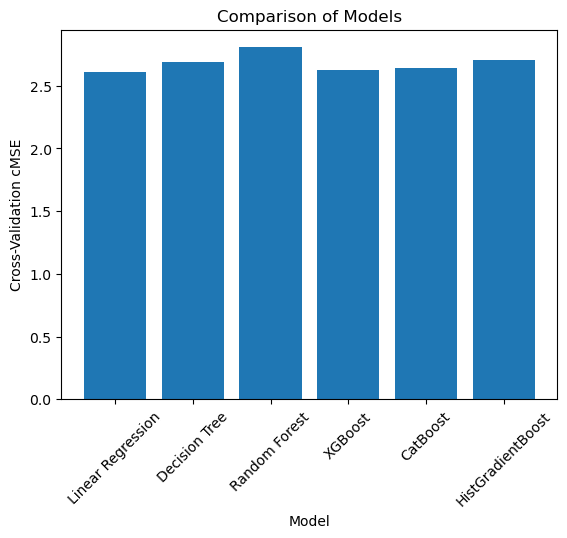

In [120]:
models = ['Linear Regression', 'Decision Tree', 'Random Forest', 'XGBoost', 'CatBoost', 'HistGradientBoost']
cMSE_values = [lr_cMSE, dt_cMSE, rf_cMSE, xgb_cMSE, cat_cMSE, hgb_cMSE]

plt.bar(models, cMSE_values)
plt.xlabel("Model")
plt.ylabel("Cross-Validation cMSE")
plt.title("Comparison of Models")
plt.xticks(rotation=45)
plt.show()

#### KNN imputer with K=19

Imputed data

In [14]:
X_imp_knn = KNNImputer(n_neighbors=19).fit_transform(X)

##### Linear Regression

In [15]:
linear_reg = make_pipeline(StandardScaler(), LinearRegression())
_, lr_cMSE, _, _ = evaluate_model(X_imp_knn, y, c, model=linear_reg)

CV cMSE: 2.587060500732423
Test cMSE: 2.4391886465016195


##### Decision Tree

In [16]:
_, dt_cMSE, _, _ = evaluate_model(X_imp_knn, y, c, model=dt_model)

CV cMSE: 2.531204378283932
Test cMSE: 2.4344804258114077


##### Random forest

In [17]:
_, rf_cMSE, _, _ = evaluate_model(X_imp_knn, y, c, model=rf_model)

CV cMSE: 2.744853821266215
Test cMSE: 3.0443563912347087


##### XGBoost

In [18]:
_, xgb_cMSE, _, _ = evaluate_model(X_imp_knn, y, c, model=xgb_model)

CV cMSE: 2.5775852399598125
Test cMSE: 2.496134669140608


##### CatBoost

In [20]:
_, cat_cMSE, _, _ = evaluate_model(X_imp_knn, y, c, model=cat_model)

CV cMSE: 2.5862339409039654
Test cMSE: 2.521504492666699


##### Histogram Gradient Boost

In [21]:
_, hgb_cMSE, _, _ = evaluate_model(X_imp_knn, y, c, model=hgb_model)

CV cMSE: 2.668070624249363
Test cMSE: 2.5242629158668666


##### Compare models through CV cMSE

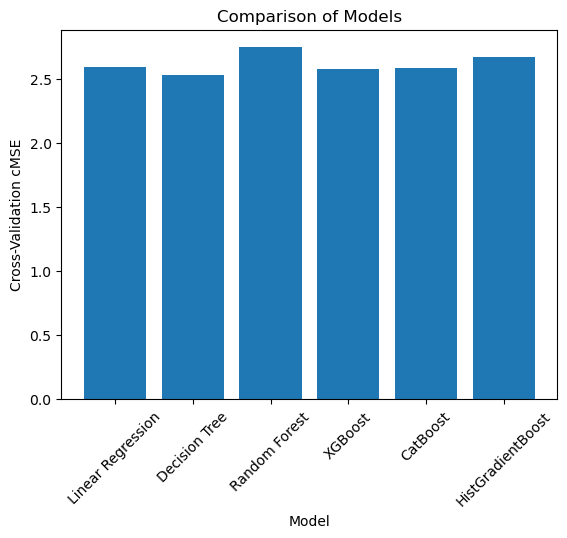

In [91]:
models = ['Linear Regression', 'Decision Tree', 'Random Forest', 'XGBoost', 'CatBoost', 'HistGradientBoost']
cMSE_values = [lr_cMSE, dt_cMSE, rf_cMSE, xgb_cMSE, cat_cMSE, hgb_cMSE]

plt.bar(models, cMSE_values)
plt.xlabel("Model")
plt.ylabel("Cross-Validation cMSE")
plt.title("Comparison of Models")
plt.xticks(rotation=45)
plt.show()

#### Iterative Imputer

Imputed data

In [93]:
X_imp_iter = IterativeImputer().fit_transform(X)

##### Linear Regression

In [94]:
linear_reg = make_pipeline(StandardScaler(), LinearRegression())
_, lr_cMSE, _, _ = evaluate_model(X_imp_iter, y, c, model=linear_reg)

CV cMSE: 2.614387285895696
Test cMSE: 2.4214396677414647


##### Decision Tree

In [95]:
_, dt_cMSE, _, _ = evaluate_model(X_imp_iter, y, c, model=dt_model)

CV cMSE: 2.631727043781623
Test cMSE: 2.4623309153759205


##### Random Forest

In [96]:
_, rf_cMSE, _, _ = evaluate_model(X_imp_iter, y, c, model=rf_model)

CV cMSE: 2.78810945387167
Test cMSE: 2.9304056898316895


##### XGBoost

In [97]:
_, xgb_cMSE, _, _ = evaluate_model(X_imp_iter, y, c, model=xgb_model)

CV cMSE: 2.634924350710497
Test cMSE: 2.4769176085306777


##### CatBoost

In [98]:
_, cat_cMSE, _, _ = evaluate_model(X_imp_iter, y, c, model=cat_model)

CV cMSE: 2.6377299403278127
Test cMSE: 2.4962271840614365


##### Histogram Gradient Boost

In [99]:
_, hgb_cMSE, _, _ = evaluate_model(X_imp_iter, y, c, model=hgb_model)

CV cMSE: 2.7292688207885925
Test cMSE: 2.521130259267931


##### Compare models through CV cMSE

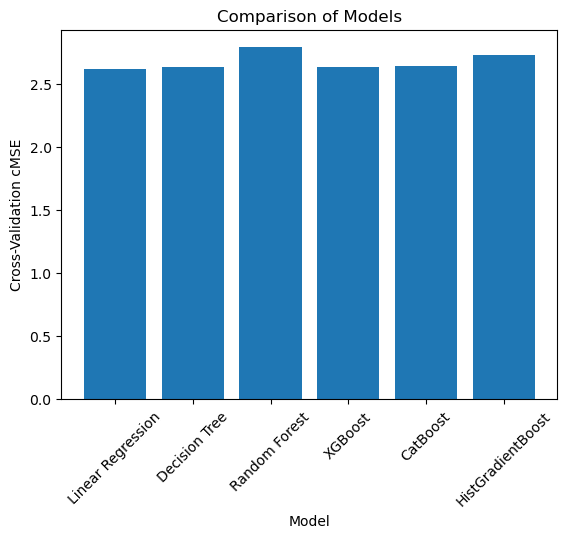

In [100]:
models = ['Linear Regression', 'Decision Tree', 'Random Forest', 'XGBoost', 'CatBoost', 'HistGradientBoost']
cMSE_values = [lr_cMSE, dt_cMSE, rf_cMSE, xgb_cMSE, cat_cMSE, hgb_cMSE]

plt.bar(models, cMSE_values)
plt.xlabel("Model")
plt.ylabel("Cross-Validation cMSE")
plt.title("Comparison of Models")
plt.xticks(rotation=45)
plt.show()

### Submission

##### Best model was CatBoost

CV cMSE: 2.5862339409039654
Test cMSE: 2.521504492666699


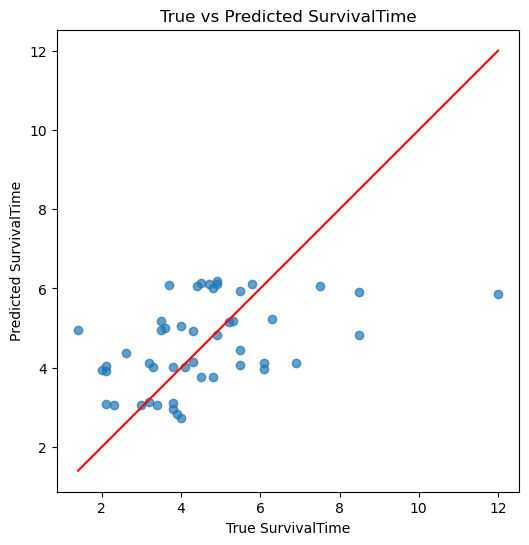

In [55]:
cat_model_knn, _, _, _ = evaluate_model(X_imp_knn, y, c, model=cat_model, show_plot=True)

#### Load Kaggle dataset and impute it

In [ ]:
X_kaggle_df = pd.read_csv('./mlNOVA/test_data.csv')
X_kaggle_df.drop(columns=['id'], inplace=True)

imputer_knn = KNNImputer(n_neighbors=19)
X_imp_knn = imputer_knn.fit_transform(X_kaggle_df)

#### Make prediction

In [83]:
y_cat_knn_pred = cat_model_knn.predict(X_imp_knn)
save_predictions(y_cat_knn_pred, './submissions/handle-missing-submission-10.csv')